In [95]:
#load libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import glob
import string
from tabulate import tabulate
import os
from pathlib import Path
import shutil
import geopandas as gpd
from shapely.geometry import Point, Polygon, LineString, box
from tqdm import tqdm
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
import math
import time
from shapely.ops import unary_union
import seaborn as sns
from scipy.spatial import cKDTree
import matplotlib.cm as cm
from matplotlib.patches import Circle
from collections import defaultdict
import pyomo.environ as pyo
import gurobipy as gp
import osmnx as ox, networkx as nx
from osmnx.distance import nearest_nodes
from descartes import PolygonPatch
import requests
import matplotlib.colors as colors
import pickle
from datetime import datetime
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

today = datetime.today().strftime("%Y%m%d")

In [96]:
ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'intermediate_result'
RESULTS_DIR = ROOT_DIR / 'results'

In [97]:
gdf_bogun = gpd.read_file(DATA_DIR / 'gdf_bogun.gpkg', encoding="utf-8-sig")
gdf_bogun.index = gdf_bogun.index.astype(str)

In [98]:
def load_selected_facilities_revised(mode, N, LAMBDA_, T, coeff, equity, base_dir = RESULTS_DIR / "optimization_results"):
    tag_map = {"free": "free", "sgg_fixed": "sgg_fixed", "sgg_relaxed": "sgg_relaxed"}
    tag = tag_map[mode]
    tag_map_1 = {"base" : "base", "revised_1" : "revised_1", "revised_2" : "revised_2"}
    tag_1 = tag_map_1[equity]
    if equity == "revised_1":
        pattern = f"*_{tag}_N{N}_lambda{LAMBDA_}_T{T}_{tag_1}_coeff{coeff}.pkl"
    elif equity == "revised_2":
        pattern = f"*_{tag}_N{N}_T{T}_{tag_1}.pkl"
    elif equity == "base":
        pattern = f"*_{tag}_N{N}_lambda{LAMBDA_}_T{T}_{tag_1}.pkl"
    candidates = sorted((Path(base_dir).glob(pattern)),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No file matched: {pattern} in {base_dir}")
    path = candidates[0]
    with open(path, "rb") as f:
        data = pickle.load(f)
    return data, path

In [99]:
lambda_ = 0.5
mode = "free"
n = 553
coeff = 0.5

In [100]:
selected, p = load_selected_facilities_revised(mode, N = n, LAMBDA_=lambda_, T=0.5, coeff=coeff, equity = "base")
selected_1, p_1 = load_selected_facilities_revised(mode, N = n, LAMBDA_=lambda_, T=0.5, coeff=coeff, equity = "revised_1")
selected_2, p_2 = load_selected_facilities_revised(mode, N = n, LAMBDA_=lambda_, T=0.5, coeff=coeff, equity = "revised_2")

In [101]:
gdf_bogun_0 = gdf_bogun.loc[gdf_bogun.index.isin(selected)]
gdf_bogun_1 = gdf_bogun.loc[gdf_bogun.index.isin(selected_1)]
gdf_bogun_2 = gdf_bogun.loc[gdf_bogun.index.isin(selected_2)]

In [102]:
import math
import pandas as pd

def recompute_grid_accessibility(
    selected_facilities,
    grid_to_inst,
    a_dict,
    Cij
):
    selected_set = set(selected_facilities)

    records = []

    for i, inst_dict in grid_to_inst.items():
        a_i = a_dict[i]

        # 선택된 시설 중 격자 i에 영향 주는 후보
        candidates = [
            j for j in inst_dict.keys()
            if j in selected_set
        ]

        chosen_j = None
        z_i = 0.0

        for j in candidates:
            # j보다 가까운 선택 시설이 있으면 탈락
            closer = Cij.get((i, j), [])
            if any(c in selected_set for c in closer):
                continue
            chosen_j = j
            z_i = inst_dict[j]
            break  # 하나만 허용

        p_i = math.sqrt(a_i + z_i)

        records.append({
            "grid_id": i,
            "a_before": a_i,
            "z": z_i,
            "a_after": a_i + z_i,
            "delta": p_i - math.sqrt(a_i),
            "chosen_facility": chosen_j
        })

    return pd.DataFrame(records)

In [103]:
path = Path(DATA_DIR / "Cij.pkl")
with open(path, "rb") as f:
    Cij = pickle.load(f)

path = Path(DATA_DIR / "a_dict.pkl")
with open(path, "rb") as f:
    a_dict = pickle.load(f)

path = Path(DATA_DIR / "grid_to_inst.pkl")
with open(path, "rb") as f:
    grid_to_inst = pickle.load(f)

In [104]:
gdf_grid_pop = pd.read_csv(DATA_DIR / 'gdf_grid_pop.csv')
gdf_emd = pd.read_csv(DATA_DIR / 'gdf_emd.csv')

In [105]:
from shapely import wkt
gdf_grid_pop['grid_centroid'] = gdf_grid_pop['grid_centroid'].apply(wkt.loads)
gdf_grid_pop['geometry'] = gdf_grid_pop['geometry'].apply(wkt.loads)
gdf_grid_pop = gpd.GeoDataFrame(
    gdf_grid_pop,
    geometry="geometry",
    crs="EPSG:5179"
)

gdf_emd['geometry'] = gdf_emd['geometry'].apply(wkt.loads)
gdf_emd = gpd.GeoDataFrame(
    gdf_emd,
    geometry="geometry",
    crs="EPSG:5179"
)   

In [106]:
df_grid = recompute_grid_accessibility(selected, grid_to_inst, a_dict, Cij)
df_grid_1 = recompute_grid_accessibility(selected_1, grid_to_inst, a_dict, Cij)
df_grid_2 = recompute_grid_accessibility(selected_2, grid_to_inst, a_dict, Cij)

In [107]:
df_grid["grid_id"] = df_grid["grid_id"].astype(str)
df_grid_1["grid_id"] = df_grid_1["grid_id"].astype(str)
df_grid_2["grid_id"] = df_grid_2["grid_id"].astype(str)
gdf_grid_pop.index = gdf_grid_pop.index.astype(str)

In [108]:
df_grid = df_grid.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how='inner')
df_grid_1 = df_grid_1.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how='inner')
df_grid_2 = df_grid_2.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how='inner')

In [109]:
df_grid = df_grid.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
df_grid_1 = df_grid_1.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
df_grid_2 = df_grid_2.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])

In [110]:
df_grid = gpd.GeoDataFrame(
    df_grid,
    geometry='geometry',
    crs=gdf_grid_pop.crs
)
df_grid_1 = gpd.GeoDataFrame(
    df_grid_1,
    geometry='geometry',
    crs=gdf_grid_pop.crs
)
df_grid_2 = gpd.GeoDataFrame(
    df_grid_2,
    geometry='geometry',
    crs=gdf_grid_pop.crs
)

In [111]:
df_grid['vulnerable'] = (df_grid['a_before'] < 0.5)
df_grid_1['vulnerable'] = (df_grid_1['a_before'] < 0.5)
df_grid_2['vulnerable'] = (df_grid_2['a_before'] < 0.5)
df_grid['resolved'] = (df_grid['vulnerable'] & (df_grid['a_after'] > 0.5))
df_grid_1['resolved'] = (df_grid_1['vulnerable'] & (df_grid_1['a_after'] > 0.5))
df_grid_2['resolved'] = (df_grid_2['vulnerable'] & (df_grid_2['a_after'] > 0.5))

In [112]:
df_grid_vulnerable = df_grid[df_grid['vulnerable'] == True]
df_grid_vulnerable_1 = df_grid_1[df_grid_1['vulnerable'] == True]
df_grid_vulnerable_2 = df_grid_2[df_grid_2['vulnerable'] == True]
df_grid_vulnerable_s = df_grid[df_grid['a_before'] < 0.3]
df_grid_vulnerable_1_s = df_grid_1[df_grid_1['a_before'] < 0.3]
df_grid_vulnerable_2_s = df_grid_2[df_grid_2['a_before'] < 0.3]
df_grid_vulnerable_r = df_grid[df_grid['a_before'] < 0.7]
df_grid_vulnerable_1_r = df_grid_1[df_grid_1['a_before'] < 0.7]
df_grid_vulnerable_2_r = df_grid_2[df_grid_2['a_before'] < 0.7]

In [113]:
df_grid['improved accessibility'] = df_grid['adjusted_population'] * df_grid['delta']
df_grid_1['improved accessibility'] = df_grid_1['adjusted_population'] * df_grid_1['delta']
df_grid_2['improved accessibility'] = df_grid_2['adjusted_population'] * df_grid_2['delta']
df_grid_vulnerable['improved accessibility'] = df_grid_vulnerable['adjusted_population'] * df_grid_vulnerable['delta']
df_grid_vulnerable_1['improved accessibility'] = df_grid_vulnerable_1['adjusted_population'] * df_grid_vulnerable_1['delta']
df_grid_vulnerable_2['improved accessibility'] = df_grid_vulnerable_2['adjusted_population'] * df_grid_vulnerable_2['delta']

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .l

In [114]:
df_grid_nonvul = df_grid.loc[~df_grid["grid_id"].isin(df_grid_vulnerable["grid_id"])]
df_grid_nonvul_1 = df_grid_1.loc[~df_grid_1["grid_id"].isin(df_grid_vulnerable_1["grid_id"])]
df_grid_nonvul_2 = df_grid_2.loc[~df_grid_2["grid_id"].isin(df_grid_vulnerable_2["grid_id"])]

In [115]:
df_grid_resolved = df_grid_vulnerable[df_grid_vulnerable['resolved'] == True]
df_grid_resolved_1 = df_grid_vulnerable_1[df_grid_vulnerable_1['resolved'] == True]
df_grid_resolved_2 = df_grid_vulnerable_2[df_grid_vulnerable_2['resolved'] == True]

In [116]:
print(f"n : {n}, mode : {mode}, lambda : {lambda_}")
print("---------------------------------------------------------------------------")
# base 결과 print
print("base")
print(f"해소 취약격자 갯수 : {len(df_grid_vulnerable[df_grid_vulnerable['a_after'] > 0.5])}")
print(f"해소 중증 취약격자 갯수 : {len(df_grid_vulnerable_s[df_grid_vulnerable_s['a_after'] > 0.3])}")
print(f"해소 우려 취약격자 갯수 : {len(df_grid_vulnerable_r[df_grid_vulnerable_r['a_after'] > 0.7])}")
print(f"접근성 상승 취약격자 갯수 : {len(df_grid_vulnerable[df_grid_vulnerable['z'] > 0])}")
print(f"취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable[df_grid_vulnerable['a_after'] > 0.5]['adjusted_population'])}")
print(f"중증 취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable_s[df_grid_vulnerable_s['a_after'] > 0.3]['adjusted_population'])}")
print(f"우려 취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable_r[df_grid_vulnerable_r['a_after'] > 0.7]['adjusted_population'])}")
print(f"향상된 인구 고려 접근성 : {df_grid[df_grid['adjusted_population'] != 0]['improved accessibility'].sum()}")
print("---------------------------------------------------------------------------")
# revised_1 결과 print
print("revised_1")
print(f"해소 취약격자 갯수 : {len(df_grid_vulnerable_1[df_grid_vulnerable_1['a_after'] > 0.5])}")
print(f"해소 중증 취약격자 갯수 : {len(df_grid_vulnerable_1_s[df_grid_vulnerable_1_s['a_after'] > 0.3])}")
print(f"해소 우려 취약격자 갯수 : {len(df_grid_vulnerable_1_r[df_grid_vulnerable_1_r['a_after'] > 0.7])}")
print(f"접근성 상승 취약격자 갯수 : {len(df_grid_vulnerable_1[df_grid_vulnerable_1['z'] > 0])}")
print(f"취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable_1[df_grid_vulnerable_1['a_after'] > 0.5]['adjusted_population'])}")
print(f"중증 취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable_1_s[df_grid_vulnerable_1_s['a_after'] > 0.3]['adjusted_population'])}")
print(f"우려 취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable_1_r[df_grid_vulnerable_1_r['a_after'] > 0.7]['adjusted_population'])}")
print(f"향상된 인구 고려 접근성 : {df_grid_1[df_grid_1['adjusted_population'] != 0]['improved accessibility'].sum()}")
print("---------------------------------------------------------------------------")
# revised_2 결과 print
print("revised_2")
print(f"해소 취약격자 갯수 : {len(df_grid_vulnerable_2[df_grid_vulnerable_2['a_after'] > 0.5])}")
print(f"해소 중증 취약격자 갯수 : {len(df_grid_vulnerable_2_s[df_grid_vulnerable_2_s['a_after'] > 0.3])}")
print(f"해소 우려 취약격자 갯수 : {len(df_grid_vulnerable_2_r[df_grid_vulnerable_2_r['a_after'] > 0.7])}")
print(f"접근성 상승 취약격자 갯수 : {len(df_grid_vulnerable_2[df_grid_vulnerable_2['z'] > 0])}")
print(f"취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable_2[df_grid_vulnerable_2['a_after'] > 0.5]['adjusted_population'])}")
print(f"중증 취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable_2_s[df_grid_vulnerable_2_s['a_after'] > 0.3]['adjusted_population'])}")
print(f"우려 취약격자 해소 수혜 인구 : {sum(df_grid_vulnerable_2_r[df_grid_vulnerable_2_r['a_after'] > 0.7]['adjusted_population'])}")
print(f"향상된 인구 고려 접근성 : {df_grid_2[df_grid_2['adjusted_population'] != 0]['improved accessibility'].sum()}")
print("---------------------------------------------------------------------------")

n : 553, mode : free, lambda : 0.5
---------------------------------------------------------------------------
base
해소 취약격자 갯수 : 8283
해소 중증 취약격자 갯수 : 4627
해소 우려 취약격자 갯수 : 14133
접근성 상승 취약격자 갯수 : 9994
취약격자 해소 수혜 인구 : 189052.27636629742
중증 취약격자 해소 수혜 인구 : 100235.93493261393
우려 취약격자 해소 수혜 인구 : 349482.0586195772
향상된 인구 고려 접근성 : 169907.30479367127
---------------------------------------------------------------------------
revised_1
해소 취약격자 갯수 : 8289
해소 중증 취약격자 갯수 : 4623
해소 우려 취약격자 갯수 : 14133
접근성 상승 취약격자 갯수 : 9967
취약격자 해소 수혜 인구 : 189204.067966106
중증 취약격자 해소 수혜 인구 : 100242.44385403559
우려 취약격자 해소 수혜 인구 : 349482.0586195772
향상된 인구 고려 접근성 : 169760.48308161844
---------------------------------------------------------------------------
revised_2
해소 취약격자 갯수 : 8292
해소 중증 취약격자 갯수 : 4634
해소 우려 취약격자 갯수 : 14194
접근성 상승 취약격자 갯수 : 9917
취약격자 해소 수혜 인구 : 189226.20990198536
중증 취약격자 해소 수혜 인구 : 100499.54086006097
우려 취약격자 해소 수혜 인구 : 350647.35063204245
향상된 인구 고려 접근성 : 163141.13277145903
-----------------------------

In [117]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch
import numpy as np

In [118]:
df_grid_only_base_1 = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_1))]
df_grid_only_base_2 = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_2))]
df_grid_only_1 = df_grid_1[df_grid_1['chosen_facility'].isin(set(selected_1) - set(selected))]
df_grid_only_2 = df_grid_2[df_grid_2['chosen_facility'].isin(set(selected_2) - set(selected))]

In [119]:
emd_access = df_grid.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_1 = df_grid_1.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_2 = df_grid_2.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")

In [120]:
emd_access_only_base_1 = df_grid_only_base_1.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_base_2 = df_grid_only_base_2.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_1 = df_grid_only_1.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_2 = df_grid_only_2.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")

In [121]:
gdf_emd_access = gdf_emd.merge(emd_access, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_1 = gdf_emd.merge(emd_access_1, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_2 = gdf_emd.merge(emd_access_2, on="EMD_CD", how = "left").fillna({"access_sum": 0})

In [122]:
gdf_emd_access_only_base_1 = gdf_emd.merge(emd_access_only_base_1, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_base_2 = gdf_emd.merge(emd_access_only_base_2, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_1 = gdf_emd.merge(emd_access_only_1, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_2 = gdf_emd.merge(emd_access_only_2, on="EMD_CD", how = "left").fillna({"access_sum": 0})

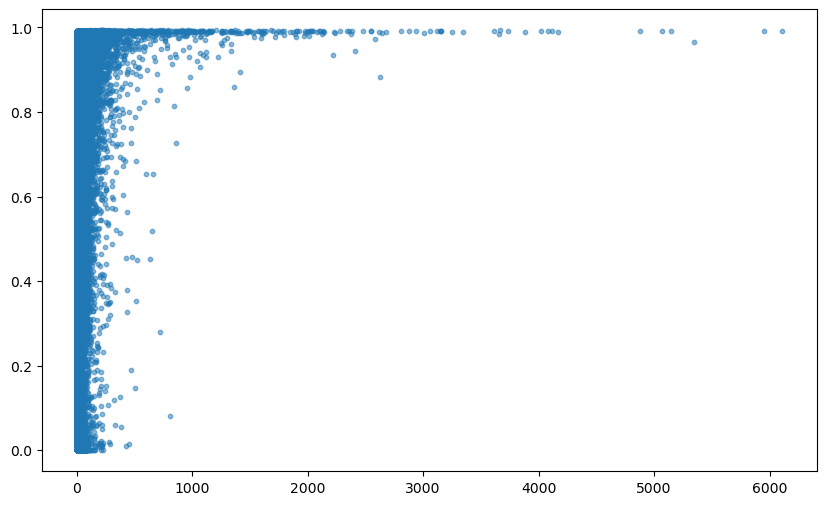

In [123]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    df_grid['adjusted_population'],
    df_grid['a_before'],
    s=10,
    alpha=0.5,
    label='base'
)

plt.show()

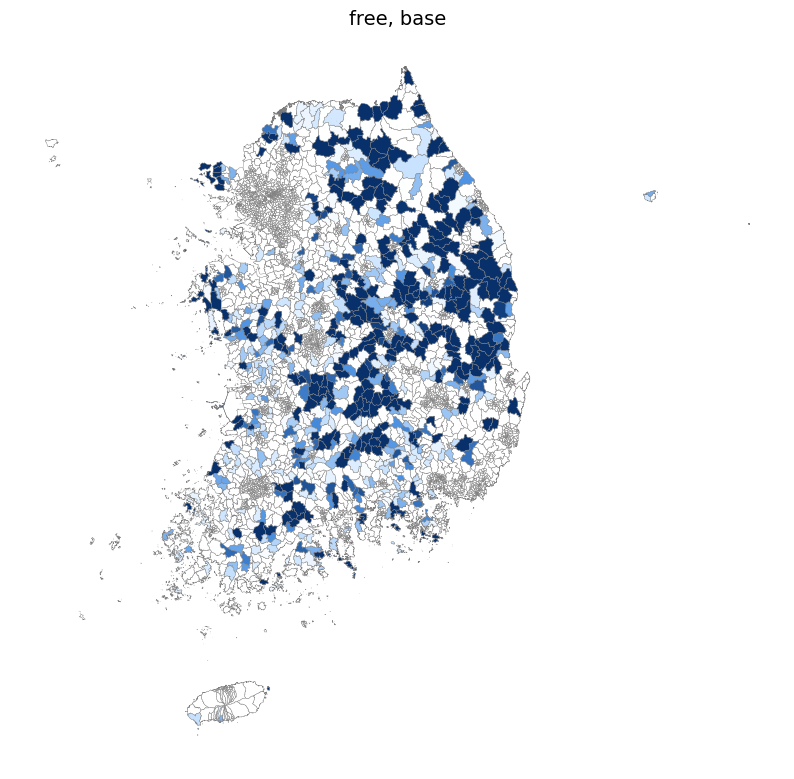

In [124]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "white_to_blue",
    ["#ffffff", "#cce5ff", "#4a90e2", "#08306b"]
)

fig, ax = plt.subplots(figsize=(10, 12))

vmax = np.abs(gdf_emd_access["access_sum"]).quantile(0.95)
vmin = 0

gdf_emd_access.plot(
    column="access_sum",
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    legend=False,
    #legend_kwds={'shrink' : 0.3},
    edgecolor="gray",
    linewidth=0.3,
    ax=ax
)

ax.set_title(f"{mode}, base", fontsize=14)
ax.axis("off")
plt.show()

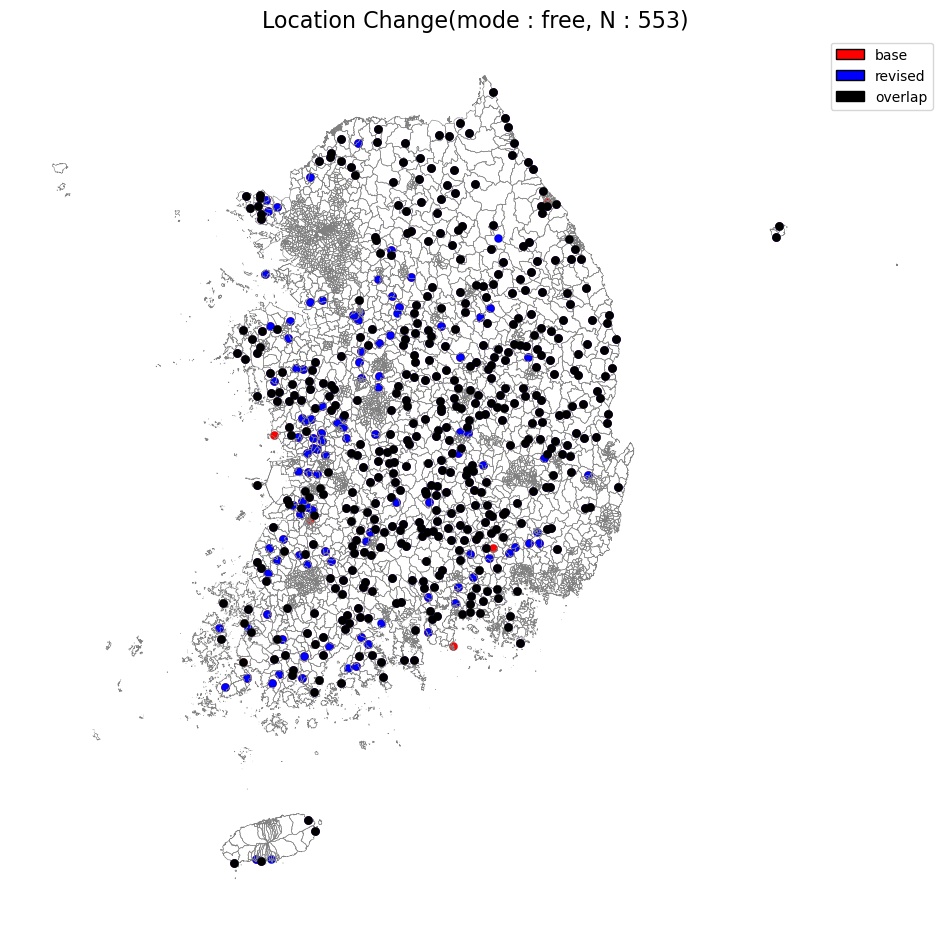

In [125]:
fig, ax = plt.subplots(figsize=(12, 14))

# 보건소
gdf_bogun_overlap = gdf_bogun.loc[gdf_bogun.index.isin(set(selected_2) & set(selected))]

gdf_bogun_0.plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_1.plot(
    ax=ax,
    facecolor='blue',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_overlap.plot(
    ax=ax,
    facecolor='black',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 10
)


# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

legend_elements = [
    Patch(facecolor='red',  edgecolor='black', label='base'),
    Patch(facecolor='blue',   edgecolor='black', label='revised'),
    Patch(facecolor='black',   edgecolor='black', label='overlap')
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=10,
    title_fontsize=11
)

ax.set_title(f"Location Change(mode : {mode}, N : {n})", fontsize=16)
ax.axis('off')

plt.show()

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


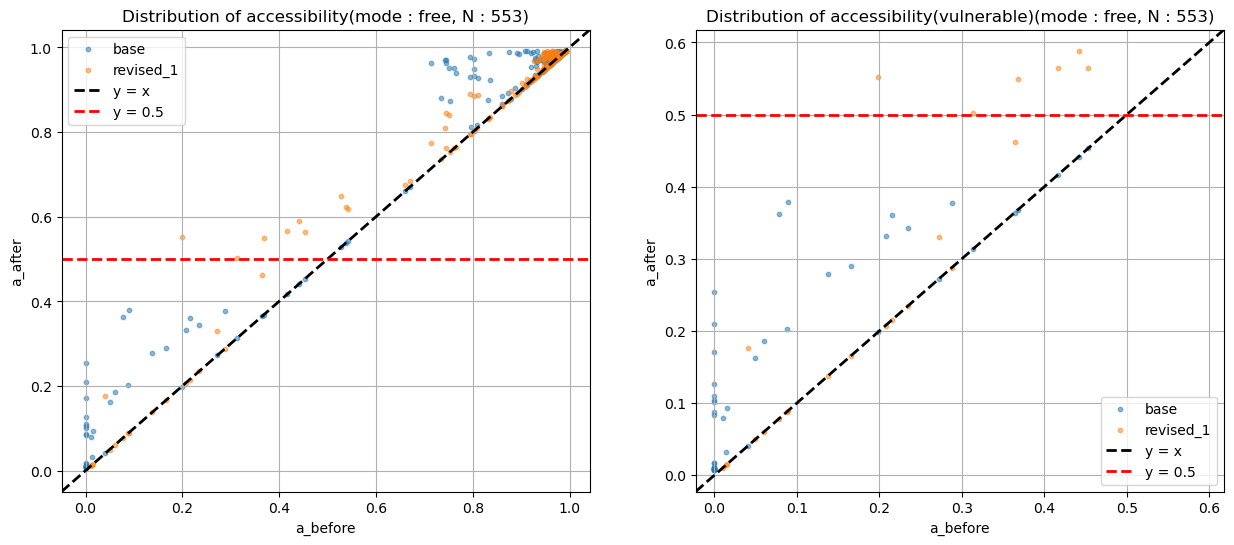

In [126]:
# revised_1, accessibility scatter

fig, axes = plt.subplots(1,2,figsize=(15, 6))

ax1, ax2 = axes

df_grid['coord'] = list(zip(df_grid['a_before'], df_grid['a_after']))
df_grid_1['coord'] = list(zip(df_grid_1['a_before'], df_grid_1['a_after']))

common = set(df_grid['coord']) & set(df_grid_1['coord'])

df_unique = df_grid[~df_grid['coord'].isin(common)]
df1_unique = df_grid_1[~df_grid_1['coord'].isin(common)]

ax1.scatter(
    df_unique['a_before'],
    df_unique['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax1.scatter(
    df1_unique['a_before'],
    df1_unique['a_after'],
    s=10,
    alpha=0.5,
    label='revised_1'
)

ax1.set_title(f'Distribution of accessibility(mode : {mode}, N : {n})')
ax1.set_xlabel('a_before')
ax1.set_ylabel('a_after')
ax1.legend()
ax1.grid(True)

df_grid_vulnerable['coord'] = list(zip(df_grid_vulnerable['a_before'], df_grid_vulnerable['a_after']))
df_grid_vulnerable_1['coord'] = list(zip(df_grid_vulnerable_1['a_before'], df_grid_vulnerable_1['a_after']))

common = set(df_grid_vulnerable['coord']) & set(df_grid_vulnerable_1['coord'])

df_unique_vulnerable = df_grid_vulnerable[~df_grid_vulnerable['coord'].isin(common)]
df1_unique_vulnerable = df_grid_vulnerable_1[~df_grid_vulnerable_1['coord'].isin(common)]

ax2.scatter(
    df_unique_vulnerable['a_before'],
    df_unique_vulnerable['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax2.scatter(
    df1_unique_vulnerable['a_before'],
    df1_unique_vulnerable['a_after'],
    s=10,
    alpha=0.5,
    label='revised_1'
)
ax2.set_title(f'Distribution of accessibility(vulnerable)(mode : {mode}, N : {n})')
ax2.set_xlabel('a_before')
ax2.set_ylabel('a_after')
ax2.legend()
ax2.grid(True)

# ===== ax1 기준선 =====
lims1 = [
    min(ax1.get_xlim()[0], ax1.get_ylim()[0]),
    max(ax1.get_xlim()[1], ax1.get_ylim()[1])
]
ax1.plot(lims1, lims1, 'k--', linewidth=2, label='y = x')
ax1.axhline(0.5, color='red', linestyle='--', linewidth=2, label='y = 0.5')
ax1.set_xlim(lims1)
ax1.set_ylim(lims1)

# ===== ax2 기준선 =====
lims2 = [
    min(ax2.get_xlim()[0], ax2.get_ylim()[0]),
    max(ax2.get_xlim()[1], ax2.get_ylim()[1])
]
ax2.plot(lims2, lims2, 'k--', linewidth=2, label='y = x')
ax2.axhline(0.5, color='red', linestyle='--', linewidth=2, label='y = 0.5')
ax2.set_xlim(lims2)
ax2.set_ylim(lims2)

ax1.legend()
ax2.legend()

plt.show()

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


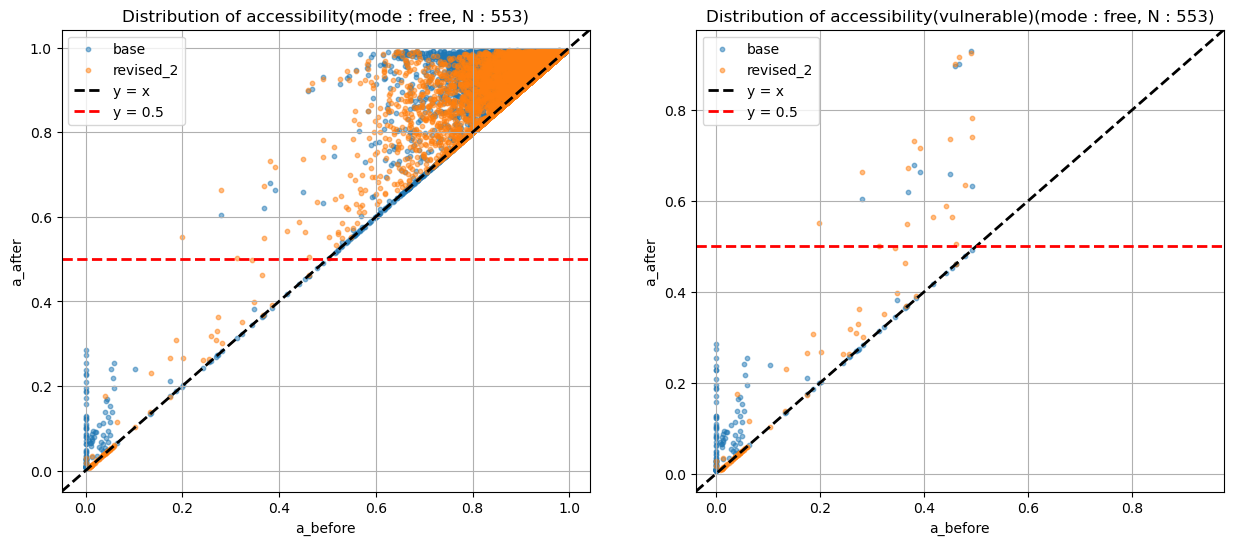

In [127]:
# revised_2, accessibility scatter

fig, axes = plt.subplots(1,2,figsize=(15, 6))

ax1, ax2 = axes

df_grid['coord'] = list(zip(df_grid['a_before'], df_grid['a_after']))
df_grid_2['coord'] = list(zip(df_grid_2['a_before'], df_grid_2['a_after']))

common = set(df_grid['coord']) & set(df_grid_2['coord'])

df_unique = df_grid[~df_grid['coord'].isin(common)]
df2_unique = df_grid_2[~df_grid_2['coord'].isin(common)]

ax1.scatter(
    df_unique['a_before'],
    df_unique['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax1.scatter(
    df2_unique['a_before'],
    df2_unique['a_after'],
    s=10,
    alpha=0.5,
    label='revised_2'
)

ax1.set_title(f'Distribution of accessibility(mode : {mode}, N : {n})')
ax1.set_xlabel('a_before')
ax1.set_ylabel('a_after')
ax1.legend()
ax1.grid(True)

df_grid_vulnerable['coord'] = list(zip(df_grid_vulnerable['a_before'], df_grid_vulnerable['a_after']))
df_grid_vulnerable_2['coord'] = list(zip(df_grid_vulnerable_2['a_before'], df_grid_vulnerable_2['a_after']))

common = set(df_grid_vulnerable['coord']) & set(df_grid_vulnerable_2['coord'])

df_unique_vulnerable = df_grid_vulnerable[~df_grid_vulnerable['coord'].isin(common)]
df2_unique_vulnerable = df_grid_vulnerable_2[~df_grid_vulnerable_2['coord'].isin(common)]

ax2.scatter(
    df_unique_vulnerable['a_before'],
    df_unique_vulnerable['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax2.scatter(
    df2_unique_vulnerable['a_before'],
    df2_unique_vulnerable['a_after'],
    s=10,
    alpha=0.5,
    label='revised_2'
)
ax2.set_title(f'Distribution of accessibility(vulnerable)(mode : {mode}, N : {n})')
ax2.set_xlabel('a_before')
ax2.set_ylabel('a_after')
ax2.legend()
ax2.grid(True)

# ===== ax1 기준선 =====
lims1 = [
    min(ax1.get_xlim()[0], ax1.get_ylim()[0]),
    max(ax1.get_xlim()[1], ax1.get_ylim()[1])
]
ax1.plot(lims1, lims1, 'k--', linewidth=2, label='y = x')
ax1.axhline(0.5, color='red', linestyle='--', linewidth=2, label='y = 0.5')
ax1.set_xlim(lims1)
ax1.set_ylim(lims1)

# ===== ax2 기준선 =====
lims2 = [
    min(ax2.get_xlim()[0], ax2.get_ylim()[0]),
    max(ax2.get_xlim()[1], ax2.get_ylim()[1])
]
ax2.plot(lims2, lims2, 'k--', linewidth=2, label='y = x')
ax2.axhline(0.5, color='red', linestyle='--', linewidth=2, label='y = 0.5')
ax2.set_xlim(lims2)
ax2.set_ylim(lims2)

ax1.legend()
ax2.legend()

plt.show()

In [128]:
grid_covered = {}
for grid in grid_to_inst.keys():
    grid_covered[grid] = 0
    for inst in grid_to_inst[grid].keys():
        if inst in selected:
            grid_covered[grid] = grid_covered[grid] + 1

grid_covered_1 = {}
for grid in grid_to_inst.keys():
    grid_covered_1[grid] = 0
    for inst in grid_to_inst[grid].keys():
        if inst in selected_1:
            grid_covered_1[grid] = grid_covered_1[grid] + 1

grid_covered_2 = {}
for grid in grid_to_inst.keys():
    grid_covered_2[grid] = 0
    for inst in grid_to_inst[grid].keys():
        if inst in selected_2:
            grid_covered_2[grid] = grid_covered_2[grid] + 1

In [129]:
grid_cov_df = pd.DataFrame({
    'grid_id': list(grid_covered.keys()),
    'covered': list(grid_covered.values())
})
grid_cov_df['grid_id'] = grid_cov_df['grid_id'].astype(str)

grid_cov_df_1 = pd.DataFrame({
    'grid_id': list(grid_covered_1.keys()),
    'covered': list(grid_covered_1.values())
})
grid_cov_df_1['grid_id'] = grid_cov_df_1['grid_id'].astype(str)

grid_cov_df_2 = pd.DataFrame({
    'grid_id': list(grid_covered_2.keys()),
    'covered': list(grid_covered_2.values())
})
grid_cov_df_2['grid_id'] = grid_cov_df_2['grid_id'].astype(str)

In [130]:
df_grid = df_grid.merge(grid_cov_df, on='grid_id', how='left')
df_grid_1 = df_grid_1.merge(grid_cov_df_1, on='grid_id', how='left')
df_grid_2 = df_grid_2.merge(grid_cov_df_2, on='grid_id', how='left')

bins = np.arange(0, df_grid['a_before'].max() + 0.05, 0.05)

df_grid['a_bin'] = pd.cut(
    df_grid['a_before'],
    bins=bins,
    include_lowest=True
)

result = (
    df_grid
    .groupby('a_bin')['covered']
    .mean()
)

df_grid_1['a_bin'] = pd.cut(
    df_grid_1['a_before'],
    bins=bins,
    include_lowest=True
)

result_1 = (
    df_grid_1
    .groupby('a_bin')['covered']
    .mean()
)

df_grid_2['a_bin'] = pd.cut(
    df_grid_2['a_before'],
    bins=bins,
    include_lowest=True
)

result_2 = (
    df_grid_2
    .groupby('a_bin')['covered']
    .mean()
)

C:\Users\hshoo\AppData\Local\Temp\ipykernel_1964\3915639043.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('a_bin')['covered']
C:\Users\hshoo\AppData\Local\Temp\ipykernel_1964\3915639043.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('a_bin')['covered']
C:\Users\hshoo\AppData\Local\Temp\ipykernel_1964\3915639043.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('a_bin')['covered'

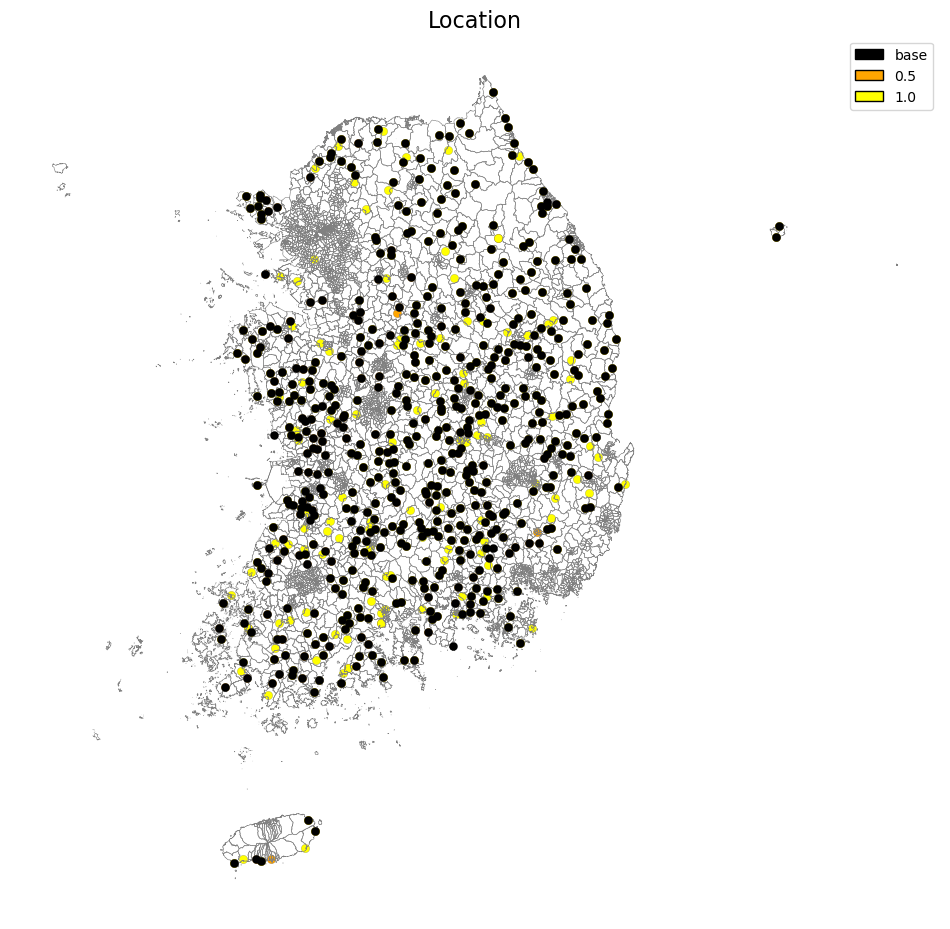

In [131]:
fig, ax = plt.subplots(figsize=(12, 14))

# 보건소

gdf_bogun_0.plot(
    ax=ax,
    facecolor='black',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 10
)
gdf_bogun_1.plot(
    ax=ax,
    facecolor='orange',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_2.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

legend_elements = [
    Patch(facecolor='black',  edgecolor='black', label='base'),
    Patch(facecolor='orange', edgecolor='black', label='0.5'),
    Patch(facecolor='yellow', edgecolor='black', label='1.0')
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=10,
    title_fontsize=11
)

ax.set_title("Location", fontsize=16)
ax.axis('off')

plt.show()

C:\Users\hshoo\AppData\Local\Temp\ipykernel_1964\503211820.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('a_bin')
C:\Users\hshoo\AppData\Local\Temp\ipykernel_1964\503211820.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('a_bin')
C:\Users\hshoo\AppData\Local\Temp\ipykernel_1964\503211820.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('a_bin')


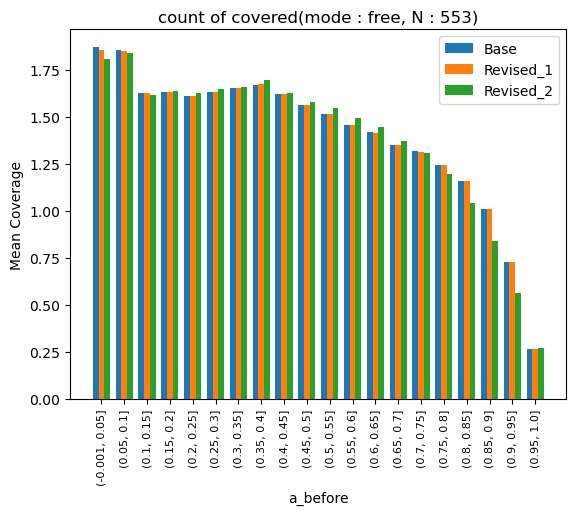

In [132]:
summary = (
    df_grid
    .groupby('a_bin')
    .agg(
        mean_coverage=('covered', 'mean'),
        n_grids=('covered', 'size')
    )
)

# revised_1
summary_1 = (
    df_grid_1
    .groupby('a_bin')
    .agg(
        mean_coverage=('covered', 'mean'),
        n_grids=('covered', 'size')
    )
)

# revised_2
summary_2 = (
    df_grid_2
    .groupby('a_bin')
    .agg(
        mean_coverage=('covered', 'mean'),
        n_grids=('covered', 'size')
    )
)

x = np.arange(len(summary.index))
width = 0.25

plt.figure()

plt.bar(x - width, summary['mean_coverage'], width, label='Base')
plt.bar(x, summary_1['mean_coverage'], width, label='Revised_1')
plt.bar(x + width, summary_2['mean_coverage'], width, label='Revised_2')

plt.xticks(x, summary.index.astype(str), rotation=90, fontsize = 8)
plt.ylabel("Mean Coverage")
plt.xlabel("a_before")
plt.legend()
plt.title(f'count of covered(mode : {mode}, N : {n})')

plt.show()

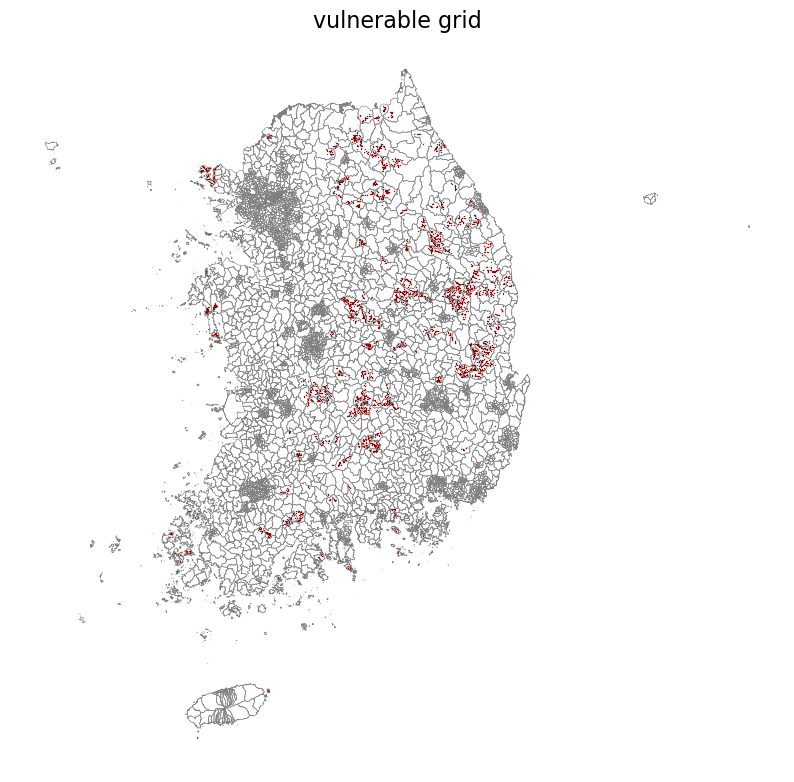

In [134]:
fig, ax = plt.subplots(figsize=(10, 10))

# 취약격자자
df_grid_vulnerable.plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

ax.set_title("vulnerable grid", fontsize=16)
ax.axis('off')

plt.show()